RGB (Color) Image → Grayscale Image

Why do we convert RGB to grayscale?

-> RGB = R + G + B

-> Gray scale is single value

RGB pixel
(100, 50, 20)

      ↓
Grayscale

     56

**CASE 1 — Mean average of three planes**



gray = ( R + G + B )/ 3

so pixel(0,0):

gray = (100+50+20)/3 = 56.67 ~ 57

so gray[0] = 57

so on we can find all others

**CASE 2 — Weighted average**

Gray=R×WR​+G×WG​+B×WB​

R = 100
, G = 50
, B = 20

WR = 0.7
, WG = 0.2
, WB = 0.1


Gray=(100×0.7)+(50×0.2)+(20×0.1)

Gray=70+10+2

Gray=82

In [ ]:
# FIRST BY DOING USING BASIC PYTHON

In [ ]:
# MEAN Avg of three panels

Saving IRONMAN Poster Design.jpg to IRONMAN Poster Design (1).jpg


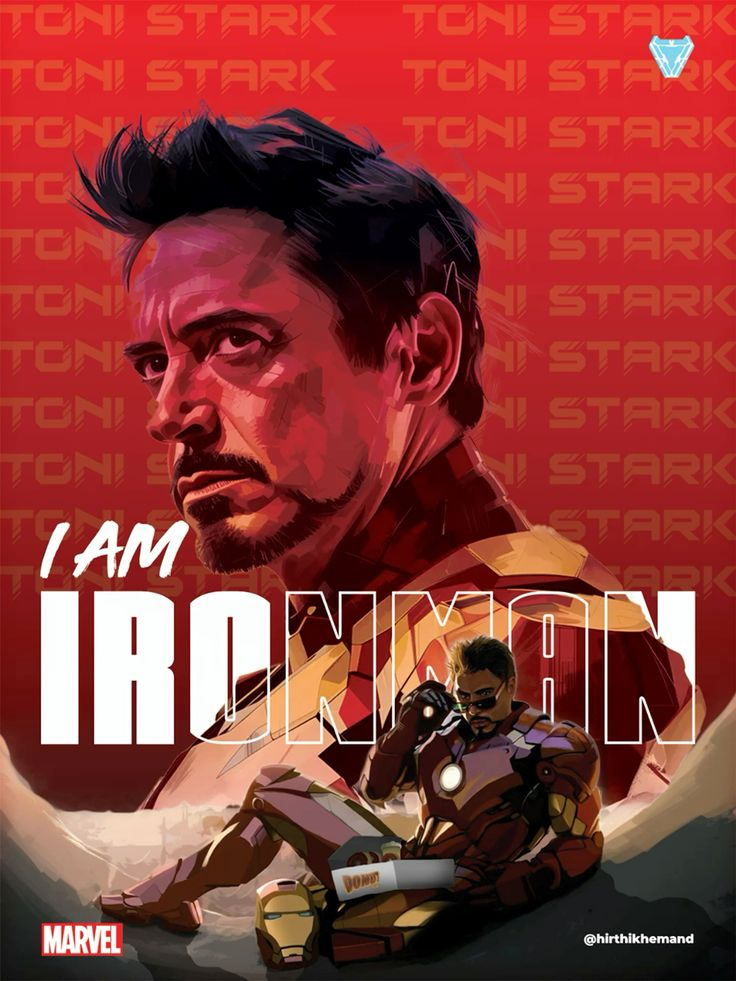

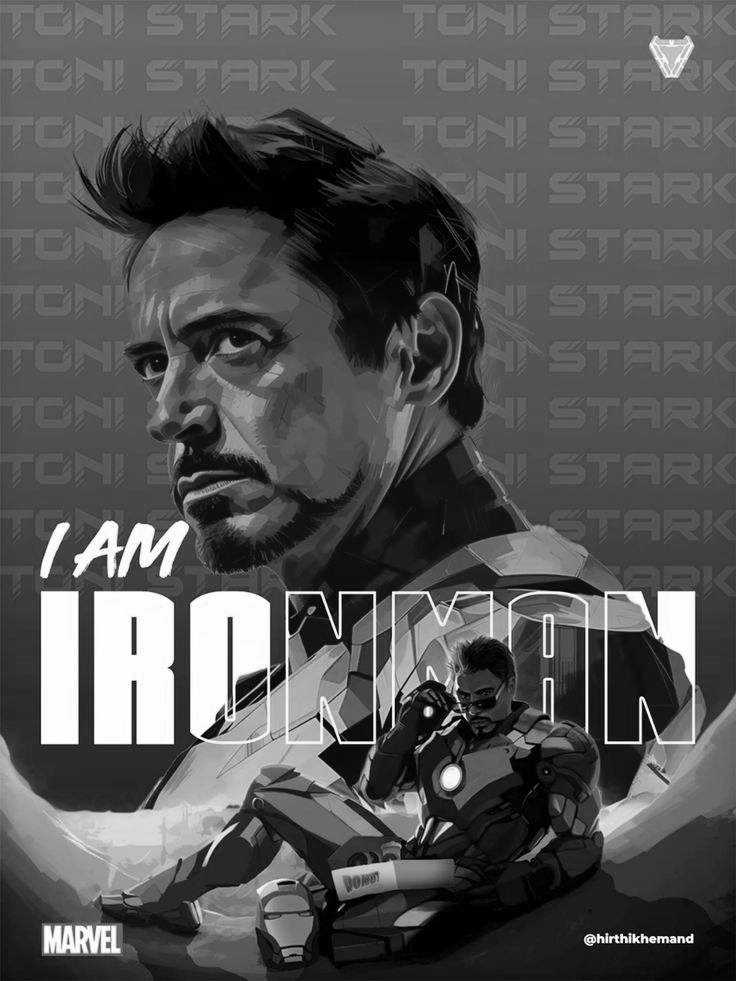

In [ ]:
from PIL import Image
from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

img = Image.open(filename).convert("RGB")

width, height = img.size

pixels = list(img.getdata())

grayscale = []

index = 0

for i in range(height):
    row = []

    for j in range(width):

        r, g, b = pixels[index]

        gray = (r + g + b) / 3

        row.append(int(gray))

        index = index + 1

    grayscale.append(row)

gray_pixels = []

for row in grayscale:
    for pixel in row:
        gray_pixels.append(pixel)

gray_image = Image.new("L", (width, height))
gray_image.putdata(gray_pixels)

display(img)
display(gray_image)

In [ ]:
# Weighted Avg of three panels

Enter weight for R: 0.7
Enter weight for G: 0.1
Enter weight for B: 0.2


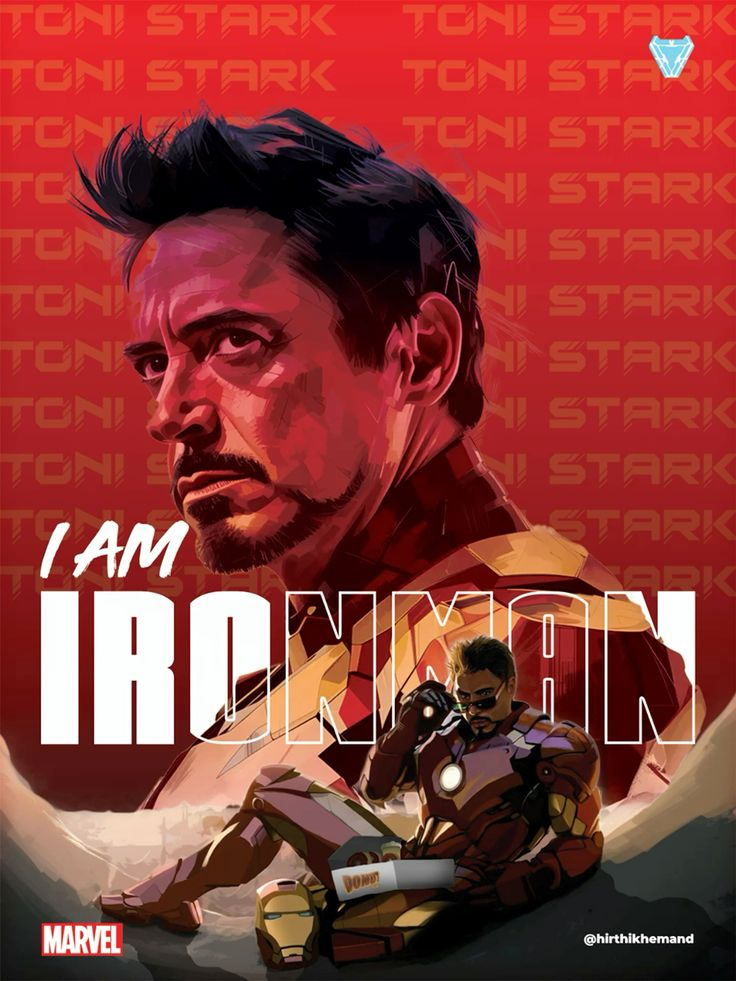

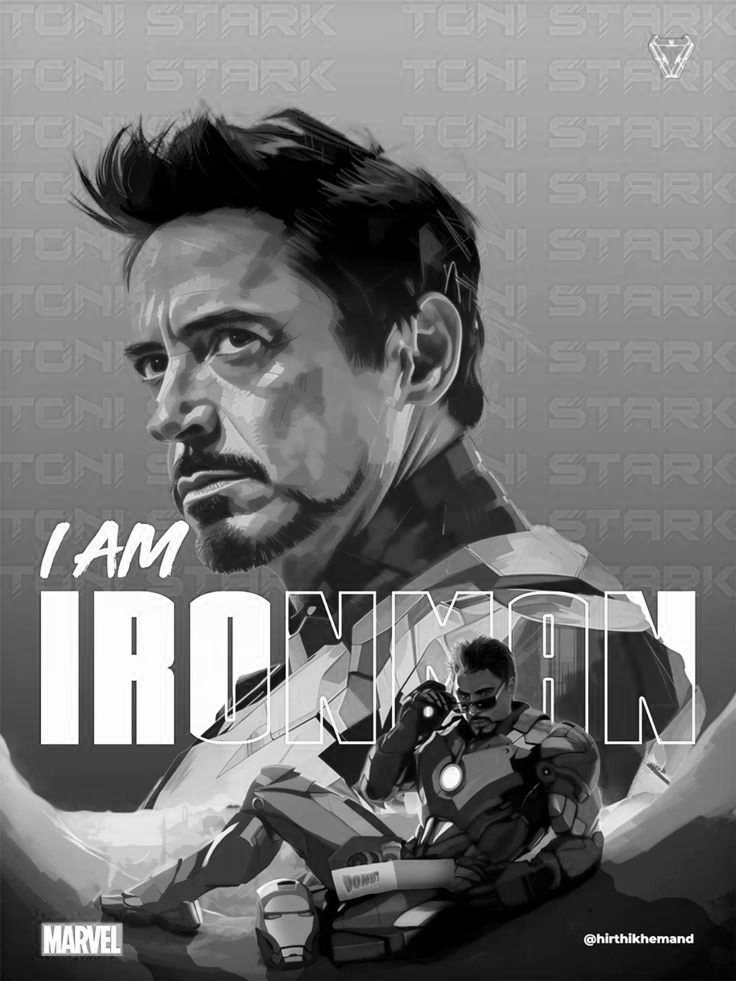

In [ ]:
wr = float(input("Enter weight for R: "))
wg = float(input("Enter weight for G: "))
wb = float(input("Enter weight for B: "))

if not (0 <= wr <= 1 and 0 <= wg <= 1 and 0 <= wb <= 1):
    print("Invalid weights")

elif abs(wr + wg + wb - 1) > 0.0001:
    print("Sum of weights must be equal to 1")

else:

    grayscale = []

    index = 0

    for i in range(height):
        row = []

        for j in range(width):

            r, g, b = pixels[index]

            gray = (r * wr) + (g * wg) + (b * wb)

            row.append(int(gray))

            index = index + 1

        grayscale.append(row)

    gray_pixels = []

    for row in grayscale:
        for pixel in row:
            gray_pixels.append(pixel)

    gray_image = Image.new("L", (width, height))
    gray_image.putdata(gray_pixels)

    display(img)
    display(gray_image)

In [ ]:
# NOW DOING IT BY OPENCV

In [ ]:
# #OpenCV reads color images as BGR, not RGB
# Channel 0 → Blue
# Channel 1 → Green
# # Channel 2 → Red

Saving 579486677097836908.jpg to 579486677097836908.jpg


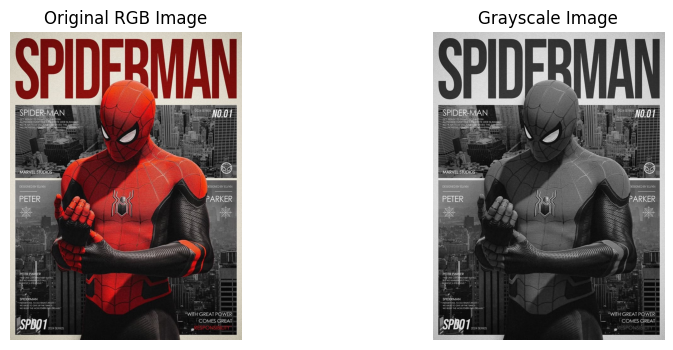

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

img = cv2.imread(filename)

b, g, r = cv2.split(img)

gray = (r.astype(float) + g.astype(float) + b.astype(float)) / 3

gray = gray.astype(np.uint8)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original RGB Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.show()

In [ ]:
# now by weighted mean method

Enter weight for R: 0.5
Enter weight for G: 0.3
Enter weight for B: 0.2


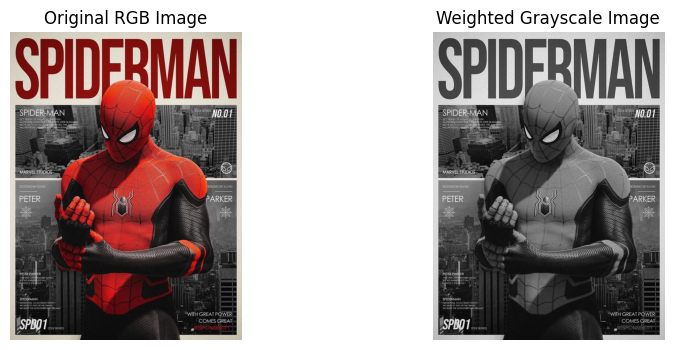

In [ ]:
wr = float(input("Enter weight for R: "))
wg = float(input("Enter weight for G: "))
wb = float(input("Enter weight for B: "))

if not (0 <= wr <= 1 and 0 <= wg <= 1 and 0 <= wb <= 1):

    print("Invalid weights")

elif abs(wr + wg + wb - 1) > 0.0001:

    print("Sum of weights must be equal to 1")

else:

    gray = (
        r.astype(float) * wr +
        g.astype(float) * wg +
        b.astype(float) * wb
    )

    gray = gray.astype(np.uint8)

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Original RGB Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(gray, cmap="gray")
    plt.title("Weighted Grayscale Image")
    plt.axis("off")

    plt.show()